# Água do Ar · Differentiated Problem Solving
**Global Solution 2026.2 · Modelagem Matemática Avançada · FIAP**

Código da modelagem. A descrição do problema, as deduções e a interpretação dos resultados estão no
`relatorio_tecnico.pdf`.

In [1]:
# Identificação
Nome_1 = "Allex Brandao"
RM_1 = "571383"

Nome_2 = "Enzo Abreu"
RM_2 = "572995"

Nome_3 = "Henrique Bueno"
RM_3 = "570591"

Nome_4 = "Murilo Gomes"
RM_4 = "570941"

## Configuração

In [2]:
import sys
from pathlib import Path

import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sympy as sp
from matplotlib import font_manager
from scipy.integrate import quad, simpson, trapezoid
from scipy.optimize import brentq, curve_fit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

NOTEBOOK = "ipykernel" in sys.modules
if NOTEBOOK:
    from IPython.display import display

try:
    BASE = Path(__file__).resolve().parent
except NameError:
    BASE = Path.cwd()
DADOS = BASE / "dados"
FIGURAS = BASE / "figuras"
FIGURAS.mkdir(exist_ok=True)

# estilo dos gráficos
fontes = {f.name for f in font_manager.fontManager.ttflist}
fonte = next((f for f in ["Latin Modern Roman", "CMU Serif", "Georgia", "DejaVu Serif"] if f in fontes),
             "DejaVu Serif")
sns.set_theme(style="whitegrid", palette="viridis", font=fonte)
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.2,
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
VIRIDIS = plt.get_cmap("viridis")
COR = {"SP": VIRIDIS(0.25), "Semiárido": VIRIDIS(0.75)}
NOMES_MES = ["", "jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]


def salvar(fig, nome):
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def tabela(df):
    if NOTEBOOK:
        display(df)
    else:
        print(df.to_string())
    return df

## 1. Dados do INMET (2023): leitura e auditoria

In [3]:
ARQ_SP = DADOS / "INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2023_A_31-12-2023.CSV"
ARQ_PETROLINA = DADOS / "INMET_NE_PE_A307_PETROLINA_01-01-2023_A_31-12-2023.CSV"
ARQ_CURACA = DADOS / "INMET_NE_BA_A448_CURACA_01-01-2023_A_31-12-2023.CSV"


def ler_inmet(caminho):
    # 8 linhas de metadados, separador ";", decimal ",", faltante = -9999
    meta = {}
    with open(caminho, encoding="latin-1") as f:
        for _ in range(8):
            partes = f.readline().strip().split(";")
            meta[partes[0].rstrip(":")] = partes[1]

    bruto = pd.read_csv(caminho, sep=";", skiprows=8, encoding="latin-1",
                        decimal=",", na_values=["-9999"])

    def coluna(trecho):
        return next(c for c in bruto.columns if trecho in c)

    hora_utc = pd.to_datetime(bruto["Data"] + " " + bruto["Hora UTC"].str[:4], format="%Y/%m/%d %H%M")
    df = pd.DataFrame({
        "ur": bruto[coluna("UMIDADE RELATIVA DO AR, HORARIA")].to_numpy(dtype=float),
        "temp": bruto[coluna("BULBO SECO")].to_numpy(dtype=float),
        "rad_kj": bruto[coluna("RADIACAO GLOBAL")].to_numpy(dtype=float),
    }, index=hora_utc - pd.Timedelta(hours=3))  # UTC -> horário local
    df.index.name = "hora_local"
    return df, meta


def tratar(df):
    df = df.copy()
    hora = df.index.hour
    # radiação em branco à noite vale zero
    noite = (hora < 7) | (hora > 18)
    df.loc[noite & df["rad_kj"].isna() & df["ur"].notna(), "rad_kj"] = 0.0
    df["rad_kj"] = df["rad_kj"].clip(lower=0)
    # interpola lacunas de até 2 h
    for c in ["ur", "temp", "rad_kj"]:
        df[c] = df[c].interpolate(limit=2, limit_area="inside")
    df["G"] = df["rad_kj"] / 3.6  # kJ/m² na hora -> W/m² médio
    return df


sp_bruto, meta_sp = ler_inmet(ARQ_SP)
pet_bruto, meta_pet = ler_inmet(ARQ_PETROLINA)
cur_bruto, meta_cur = ler_inmet(ARQ_CURACA)

# Semiárido: umidade e temperatura de Petrolina + radiação de Curaçá
semi_bruto = pet_bruto.copy()
semi_bruto["rad_kj"] = cur_bruto["rad_kj"].reindex(semi_bruto.index)

clima = {"SP": tratar(sp_bruto), "Semiárido": tratar(semi_bruto)}

for nome, meta in [("São Paulo", meta_sp), ("Petrolina", meta_pet), ("Curaçá", meta_cur)]:
    print(f"{nome:10s} | {meta['ESTACAO']:20s} | {meta['CODIGO (WMO)']} | "
          f"lat {meta['LATITUDE']} | lon {meta['LONGITUDE']} | alt {meta['ALTITUDE']} m")

São Paulo  | SAO PAULO - MIRANTE  | A701 | lat -23,49638888 | lon -46,61999999 | alt 785,64 m
Petrolina  | PETROLINA            | A307 | lat -9,38833333 | lon -40,52333332 | alt 372,72 m
Curaçá     | CURACA               | A448 | lat -9,00138888 | lon -39,9125 | alt 370 m


In [4]:
# auditoria das séries
def auditar(df_bruto, df):
    return pd.Series({
        "Registros horários": len(df_bruto),
        "Horas duplicadas": int(df_bruto.index.duplicated().sum()),
        "UR faltante (bruto)": int(df_bruto["ur"].isna().sum()),
        "Temperatura faltante (bruto)": int(df_bruto["temp"].isna().sum()),
        "Radiação faltante (bruto)": int(df_bruto["rad_kj"].isna().sum()),
        "UR fora de [0, 100] %": int(((df["ur"] < 0) | (df["ur"] > 100)).sum()),
        "Temperatura fora de [-5, 45] °C": int(((df["temp"] < -5) | (df["temp"] > 45)).sum()),
        "Radiação negativa": int((df_bruto["rad_kj"] < 0).sum()),
    })


tabela(pd.DataFrame({"SP": auditar(sp_bruto, clima["SP"]),
                     "Semiárido": auditar(semi_bruto, clima["Semiárido"])}))


def dias_completos(df):
    # dias com as 24 horas válidas nas três variáveis
    dia = (df.index - pd.Timedelta(minutes=1)).normalize()
    validos = df[["ur", "temp", "G"]].notna().all(axis=1)
    contagem = validos.groupby(dia).sum()
    return contagem[contagem == 24].index


cobertura = pd.DataFrame({
    terr: pd.Series(dias_completos(df)).dt.month.value_counts().sort_index()
    for terr, df in clima.items()
}).reindex(range(1, 13)).fillna(0).astype(int)
cobertura.index.name = "mês"
print("Dias completos por mês:")
tabela(cobertura.T)

,SP,Semiárido
Registros horários,8760,8760
Horas duplicadas,0,0
UR faltante (bruto),212,2965
Temperatura faltante (bruto),212,2965
Radiação faltante (bruto),4171,5602
"UR fora de [0, 100] %",0,0
"Temperatura fora de [-5, 45] °C",0,0
Radiação negativa,0,0


Dias completos por mês:


mês,1,2,3,4,5,6,7,8,9,10,11,12
SP,29,27,31,29,28,29,25,29,28,31,25,30
Semiárido,0,0,0,0,28,30,31,31,30,31,30,28


mês,1,2,3,4,5,6,7,8,9,10,11,12
SP,29,27,31,29,28,29,25,29,28,31,25,30
Semiárido,0,0,0,0,28,30,31,31,30,31,30,28


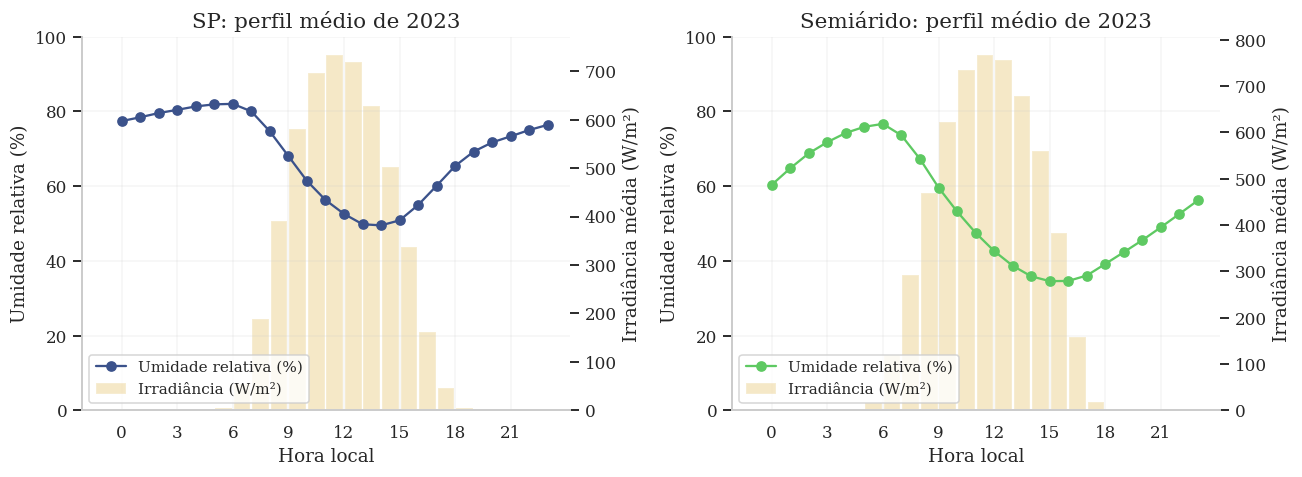

In [5]:
# perfil médio horário de umidade e irradiância
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
for (terr, df), ax in zip(clima.items(), eixos):
    perfil = df.groupby(df.index.hour)[["ur", "G"]].mean()
    ax.plot(perfil.index, perfil["ur"], "o-", color=COR[terr], label="Umidade relativa (%)")
    ax.set(xlabel="Hora local", ylabel="Umidade relativa (%)", title=f"{terr}: perfil médio de 2023",
           ylim=(0, 100), xticks=range(0, 24, 3))
    ax2 = ax.twinx()
    ax2.bar(perfil.index - 0.5, perfil["G"], width=0.9, alpha=0.25, color="goldenrod",
            label="Irradiância (W/m²)")
    ax2.set_ylabel("Irradiância média (W/m²)")
    ax2.grid(False)
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)
    linhas = ax.get_legend_handles_labels()
    barras = ax2.get_legend_handles_labels()
    ax.legend(linhas[0] + barras[0], linhas[1] + barras[1], loc="lower left")
salvar(fig, "01_perfil_medio_inmet")

## 2. MOF: isoterma, limites e cinética

In [6]:
# isoterma logística do MOF-303 (Hanikel et al., 2019)
ETA_COND = 0.85            # eficiência de condensação
U_INFLEXAO = 12.0          # %
Q_20 = 0.39                # L/kg a 20 % de UR
Q_MAX = Q_20 / 0.95        # hipótese: 95 % da capacidade a 20 %
K_ISO = np.log(19) / (20 - U_INFLEXAO)


def q_eq(u):
    return Q_MAX / (1 + np.exp(-K_ISO * (u - U_INFLEXAO)))


def dq_eq(u):
    q = q_eq(u)
    return K_ISO * q * (1 - q / Q_MAX)


# limites com SymPy
u_s = sp.symbols("u", real=True)
q_sym = sp.Float(Q_MAX, 6) / (1 + sp.exp(-sp.Float(K_ISO, 6) * (u_s - U_INFLEXAO)))
print("lim u→+∞ q_eq(u) =", sp.limit(q_sym, u_s, sp.oo))
print("lim u→−∞ q_eq(u) =", sp.limit(q_sym, u_s, -sp.oo))
print(f"q_max = {Q_MAX:.4f} L/kg | k = {K_ISO:.4f} por ponto percentual")

# derivada: fórmula fechada x SymPy
derivada_sym = sp.lambdify(u_s, sp.diff(q_sym, u_s), "numpy")
u_teste = np.array([5, 12, 20, 32, 45, 60, 80])
tabela(pd.DataFrame({
    "UR (%)": u_teste,
    "q_eq (L/kg)": q_eq(u_teste),
    "q_eq' fórmula (L/kg por %)": dq_eq(u_teste),
    "q_eq' SymPy (L/kg por %)": derivada_sym(u_teste),
}))

lim u→+∞ q_eq(u) = 39/95
lim u→−∞ q_eq(u) = 0
q_max = 0.4105 L/kg | k = 0.3681 por ponto percentual


,UR (%),q_eq (L/kg),q_eq' fórmula (L/kg por %),q_eq' SymPy (L/kg por %)
0,5,0.0290,0.0099,0.0099
1,12,0.2053,0.0378,0.0378
2,20,0.3900,0.0072,0.0072
3,32,0.4103,0.0001,0.0001
4,45,0.4105,0.0000,0.0000
5,60,0.4105,0.0000,0.0000
6,80,0.4105,0.0000,0.0000


,UR (%),q_eq (L/kg),q_eq' fórmula (L/kg por %),q_eq' SymPy (L/kg por %)
0,5,0.0290,0.0099,0.0099
1,12,0.2053,0.0378,0.0378
2,20,0.3900,0.0072,0.0072
3,32,0.4103,0.0001,0.0001
4,45,0.4105,0.0000,0.0000
5,60,0.4105,0.0000,0.0000
6,80,0.4105,0.0000,0.0000


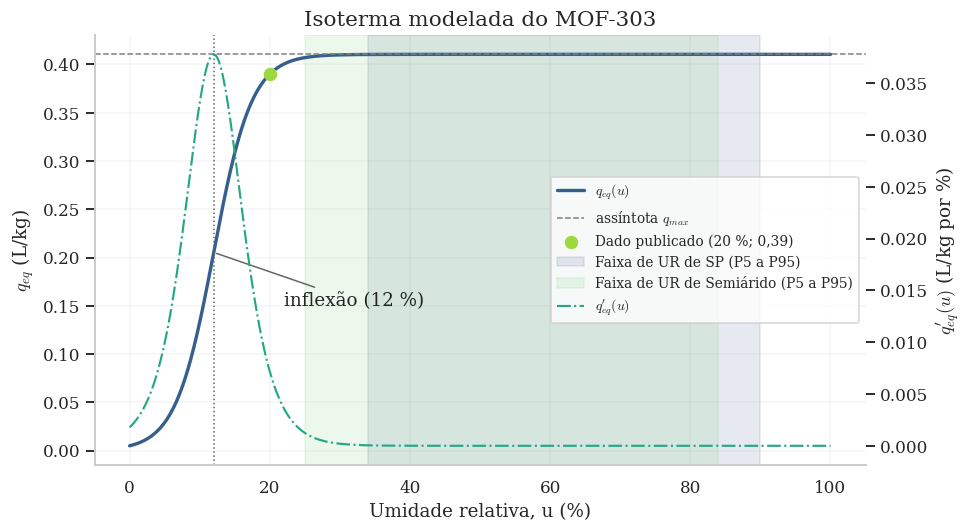

In [7]:
# gráfico da isoterma e da derivada
u_malha = np.linspace(0, 100, 600)
fig, ax = plt.subplots()
ax.plot(u_malha, q_eq(u_malha), color=VIRIDIS(0.3), lw=2.2, label=r"$q_{eq}(u)$")
ax.axhline(Q_MAX, ls="--", color="0.5", lw=1, label=r"assíntota $q_{max}$")
ax.scatter([20], [Q_20], color=VIRIDIS(0.85), zorder=5, s=60, label="Dado publicado (20 %; 0,39)")
ax.axvline(U_INFLEXAO, ls=":", color="0.4", lw=1)
ax.annotate("inflexão (12 %)", xy=(U_INFLEXAO, Q_MAX / 2), xytext=(22, 0.15),
            arrowprops={"arrowstyle": "-", "color": "0.4"})
for terr, df in clima.items():
    ax.axvspan(df["ur"].quantile(0.05), df["ur"].quantile(0.95), alpha=0.12, color=COR[terr],
               label=f"Faixa de UR de {terr} (P5 a P95)")
ax2 = ax.twinx()
ax2.plot(u_malha, dq_eq(u_malha), color=VIRIDIS(0.6), lw=1.4, ls="-.", label=r"$q_{eq}'(u)$")
ax2.set_ylabel(r"$q_{eq}'(u)$ (L/kg por %)")
ax2.grid(False)
ax.set(xlabel="Umidade relativa, u (%)", ylabel=r"$q_{eq}$ (L/kg)", title="Isoterma modelada do MOF-303")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right", fontsize=9)
salvar(fig, "02_isoterma")

In [8]:
# cinética LDF: calibração de θ com o ensaio de 9 ciclos/dia (1,3 L/kg a 27 °C e 32 %)
TAU_D = 1.0                       # h, dessorção
CICLOS_REF, PROD_REF = 9, 1.3
U_REF, T_REF = 32.0, 27.0
TAU_A_REF = 24 / CICLOS_REF - TAU_D


def pressao_saturacao(T):
    # Tetens, kPa
    return 0.6108 * np.exp(17.27 * T / (T + 237.3))


def pressao_vapor(u, T):
    return u / 100 * pressao_saturacao(T)


E_REF = pressao_vapor(U_REF, T_REF)
fracao = PROD_REF / (CICLOS_REF * ETA_COND * q_eq(U_REF))
THETA_REF = -TAU_A_REF / np.log(1 - fracao)  # solução fechada


def residuo_calibracao(theta):
    return CICLOS_REF * ETA_COND * q_eq(U_REF) * (1 - np.exp(-TAU_A_REF / theta)) - PROD_REF


theta_brent = brentq(residuo_calibracao, 0.1, 50)  # conferência numérica


def theta(u, T):
    # constante de tempo inversamente proporcional à pressão de vapor
    return THETA_REF * E_REF / pressao_vapor(u, T)


print(f"e_ref = {E_REF:.3f} kPa | fração de enchimento por ciclo = {fracao:.4f}")
print(f"θ_ref fórmula = {THETA_REF:.4f} h | θ_ref Brent = {theta_brent:.4f} h | "
      f"diferença = {abs(THETA_REF - theta_brent):.2e} h")

pv = pd.DataFrame({
    terr: {
        "UR média (%)": df["ur"].mean(),
        "T média (°C)": df["temp"].mean(),
        "Pressão de vapor média (kPa)": pressao_vapor(df["ur"], df["temp"]).mean(),
        "θ médio (h)": theta(df["ur"], df["temp"]).mean(),
    } for terr, df in clima.items()
})
pv["Ensaio de referência"] = [U_REF, T_REF, E_REF, THETA_REF]
tabela(pv)

e_ref = 1.141 kPa | fração de enchimento por ciclo = 0.4142
θ_ref fórmula = 3.1165 h | θ_ref Brent = 3.1165 h | diferença = 4.34e-13 h


,SP,Semiárido,Ensaio de referência
UR média (%),68.7344,54.1780,32.0000
T média (°C),21.1690,27.5339,27.0000
Pressão de vapor média (kPa),1.6872,1.8882,1.1409
θ médio (h),2.2139,1.9571,3.1165


,SP,Semiárido,Ensaio de referência
UR média (%),68.7344,54.1780,32.0000
T média (°C),21.1690,27.5339,27.0000
Pressão de vapor média (kPa),1.6872,1.8882,1.1409
θ médio (h),2.2139,1.9571,3.1165


## 3. Ciclo ótimo: limites, derivada e Newton

In [9]:
# R(τ) simbólica: limites e derivada
tau, th, td, A_s = sp.symbols("tau theta tau_d A", positive=True)
R_sym = A_s * (1 - sp.exp(-tau / th)) / (tau + td)

print("lim τ→0+  R(τ) =", sp.limit(R_sym, tau, 0, "+"))
print("lim τ→+∞  R(τ) =", sp.limit(R_sym, tau, sp.oo))
print("lim τ→0+  R(τ) com τ_d = 0 :", sp.limit(R_sym.subs(td, 0), tau, 0, "+"))

dR_sym = sp.simplify(sp.diff(R_sym, tau))
print("\nR'(τ) =", dR_sym)
print("numerador de R'(τ):", sp.simplify(sp.numer(sp.together(dR_sym))))

lim τ→0+  R(τ) =

 0
lim τ→+∞  R(τ) = 0
lim τ→0+  R(τ) com τ_d = 0 : A/theta



R'(τ) = A*(tau + tau_d + theta*(1 - exp(tau/theta)))*exp(-tau/theta)/(theta*(tau + tau_d)**2)
numerador de R'(τ): A*(tau + tau_d + theta*(1 - exp(tau/theta)))


In [10]:
# Newton para e^x = 1 + x + δ, com chute x0 = sqrt(2δ); conferência pelo método de Brent
def newton_x(delta, tol=1e-12, max_iter=50, historico=False):
    delta = np.asarray(delta, dtype=float)
    x = np.sqrt(2 * delta)
    passos = [x.copy()]
    for _ in range(max_iter):
        passo = (np.exp(x) - 1 - x - delta) / (np.exp(x) - 1)
        x = x - passo
        passos.append(x.copy())
        if np.all(np.abs(passo) < tol):
            break
    return (x, passos) if historico else x


def x_brent(delta):
    # g(0) = -δ < 0 e g(5) > 0: a raiz está em (0, 5)
    return brentq(lambda x: np.exp(x) - 1 - x - delta, 1e-9, 5)


def taxa_R(tau_a, u, T, tau_d=TAU_D):
    th_ = theta(u, T)
    return ETA_COND * q_eq(u) * (1 - np.exp(-tau_a / th_)) / (tau_a + tau_d)


def ciclo_otimo(u, T, tau_d=TAU_D):
    th_ = theta(u, T)
    x = newton_x(tau_d / th_)
    tau_star = x * th_
    return {
        "theta": th_,
        "x": x,
        "tau_a": tau_star,
        "ciclos_24h": 24 / (tau_star + tau_d),
        "R": ETA_COND * q_eq(u) * np.exp(-x) / th_,  # R* = A e^(-x*) / θ
    }


delta_ref = TAU_D / THETA_REF
x_ref, passos = newton_x(delta_ref, historico=True)
print(f"θ = {THETA_REF:.4f} h, δ = {delta_ref:.4f}")
tabela(pd.DataFrame({
    "iteração": range(len(passos)),
    "x_n": [float(p) for p in passos],
    "g(x_n)": [float(np.exp(p) - 1 - p - delta_ref) for p in passos],
}))
print(f"x* Newton = {float(x_ref):.10f}")
print(f"x* Brent  = {x_brent(delta_ref):.10f}")

ref = ciclo_otimo(U_REF, T_REF)
R_hanikel = taxa_R(TAU_A_REF, U_REF, T_REF)
tau_num = brentq(lambda t: taxa_R(t + 1e-6, U_REF, T_REF) - taxa_R(t - 1e-6, U_REF, T_REF), 0.05, 20)

θ = 3.1165 h, δ = 0.3209


,iteração,x_n,g(x_n)
0,0,0.8011,0.1060
1,1,0.7148,0.0081
2,2,0.7070,0.0001
3,3,0.7070,0.0000
4,4,0.7070,-0.0000
5,5,0.7070,-0.0000


x* Newton = 0.7069749483
x* Brent  = 0.7069749483


In [11]:
# classificação do ponto crítico: sinal de R' e R''
valores_ref = {A_s: ETA_COND * q_eq(U_REF), th: THETA_REF, td: TAU_D}
dR_num = sp.lambdify(tau, dR_sym.subs(valores_ref), "numpy")
d2R_num = sp.lambdify(tau, sp.diff(R_sym, tau, 2).subs(valores_ref), "numpy")
tau_star_ref = float(ref["tau_a"])

tabela(pd.DataFrame({
    "τ (h)": [tau_star_ref - 0.5, tau_star_ref, tau_star_ref + 0.5],
    "R'(τ) (L/kg/h²)": [dR_num(tau_star_ref - 0.5), dR_num(tau_star_ref), dR_num(tau_star_ref + 0.5)],
}))
print(f"R''(τ*) = {d2R_num(tau_star_ref):.5f} L/kg/h³")
print(f"R'(τ) = 0 por diferenças centrais + Brent: τ = {tau_num:.4f} h")
print(f"Ótimo: τ* = {tau_star_ref:.4f} h | {float(ref['ciclos_24h']):.2f} ciclos/dia | "
      f"{24 * float(ref['R']):.4f} L/kg/dia")
print(f"Ensaio (9 ciclos): {24 * R_hanikel:.4f} L/kg/dia | ganho do ótimo = "
      f"{100 * (float(ref['R']) / R_hanikel - 1):.2f} %")

,τ (h),R'(τ) (L/kg/h²)
0,1.7033,0.0039
1,2.2033,0.0000
2,2.7033,-0.0021


R''(τ*) = -0.00553 L/kg/h³
R'(τ) = 0 por diferenças centrais + Brent: τ = 2.2033 h
Ótimo: τ* = 2.2033 h | 7.49 ciclos/dia | 1.3243 L/kg/dia
Ensaio (9 ciclos): 1.3000 L/kg/dia | ganho do ótimo = 1.87 %


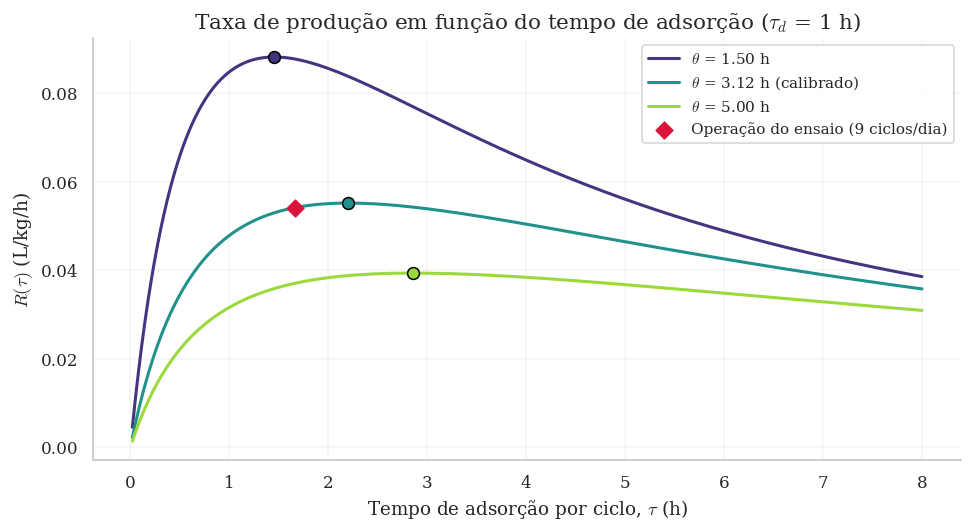

In [12]:
# R(τ) para três valores de θ
tau_malha = np.linspace(0.02, 8, 500)
fig, ax = plt.subplots()
for i, th_v in enumerate([1.5, THETA_REF, 5.0]):
    R_curva = ETA_COND * q_eq(U_REF) * (1 - np.exp(-tau_malha / th_v)) / (tau_malha + TAU_D)
    x_v = float(newton_x(TAU_D / th_v))
    R_max = ETA_COND * q_eq(U_REF) * np.exp(-x_v) / th_v
    cor = VIRIDIS(0.15 + 0.35 * i)
    rotulo = rf"$\theta$ = {th_v:.2f} h" + (" (calibrado)" if i == 1 else "")
    ax.plot(tau_malha, R_curva, color=cor, lw=2, label=rotulo)
    ax.scatter([x_v * th_v], [R_max], color=cor, s=60, zorder=5, edgecolor="k")
ax.scatter([TAU_A_REF], [R_hanikel], marker="D", color="crimson", s=60, zorder=6,
           label="Operação do ensaio (9 ciclos/dia)")
ax.set(xlabel=r"Tempo de adsorção por ciclo, $\tau$ (h)", ylabel=r"$R(\tau)$ (L/kg/h)",
       title=r"Taxa de produção em função do tempo de adsorção ($\tau_d$ = 1 h)")
ax.legend()
salvar(fig, "03_ciclo_otimo")

In [13]:
# sensibilidade a θ e τ_d
linhas = []
for th_v in [1.0, 2.0, THETA_REF, 4.0, 6.0]:
    for td_v in [0.5, 1.0, 1.5]:
        x_v = float(newton_x(td_v / th_v))
        R_v = ETA_COND * Q_MAX * np.exp(-x_v) / th_v
        linhas.append({"θ (h)": th_v, "τ_d (h)": td_v, "δ": td_v / th_v, "x*": x_v,
                       "τ* (h)": x_v * th_v, "ciclos/24 h": 24 / (x_v * th_v + td_v),
                       "R* (L/kg/dia, 24 h)": 24 * R_v})
tabela(pd.DataFrame(linhas))

,θ (h),τ_d (h),δ,x*,τ* (h),ciclos/24 h,"R* (L/kg/dia, 24 h)"
0,1.0000,0.5000,0.5000,0.8577,0.8577,17.6773,3.5521
1,1.0000,1.0000,1.0000,1.1462,1.1462,11.1826,2.6619
2,1.0000,1.5000,1.5000,1.3474,1.3474,8.4288,2.1767
3,2.0000,0.5000,0.2500,0.6327,1.2654,13.5944,2.2241
4,2.0000,1.0000,0.5000,0.8577,1.7154,8.8386,1.7761
5,2.0000,1.5000,0.7500,1.0182,2.0364,6.7866,1.5127
6,3.1165,0.5000,0.1604,0.5177,1.6133,11.3567,1.6014
7,3.1165,1.0000,0.3209,0.7070,2.2033,7.4923,1.3252
8,3.1165,1.5000,0.4813,0.8437,2.6295,5.8118,1.1558
9,4.0000,0.5000,0.1250,0.4616,1.8463,10.2287,1.3196


,θ (h),τ_d (h),δ,x*,τ* (h),ciclos/24 h,"R* (L/kg/dia, 24 h)"
0,1.0000,0.5000,0.5000,0.8577,0.8577,17.6773,3.5521
1,1.0000,1.0000,1.0000,1.1462,1.1462,11.1826,2.6619
2,1.0000,1.5000,1.5000,1.3474,1.3474,8.4288,2.1767
3,2.0000,0.5000,0.2500,0.6327,1.2654,13.5944,2.2241
4,2.0000,1.0000,0.5000,0.8577,1.7154,8.8386,1.7761
5,2.0000,1.5000,0.7500,1.0182,2.0364,6.7866,1.5127
6,3.1165,0.5000,0.1604,0.5177,1.6133,11.3567,1.6014
7,3.1165,1.0000,0.3209,0.7070,2.2033,7.4923,1.3252
8,3.1165,1.5000,0.4813,0.8437,2.6295,5.8118,1.1558
9,4.0000,0.5000,0.1250,0.4616,1.8463,10.2287,1.3196


## 4. Simulador mês a mês com o clima real

In [14]:
G_NOITE, G_REF = 50.0, 600.0  # W/m²


def fator_climatico(G):
    # rampa: 0 abaixo de G_NOITE, 1 acima de G_REF
    return np.clip((np.asarray(G, dtype=float) - G_NOITE) / (G_REF - G_NOITE), 0, 1)


def intervalos(df):
    # cada registro representa o intervalo (h-1, h]; UR e T = média dos extremos
    d = pd.DataFrame(index=df.index)
    d["ur"] = (df["ur"] + df["ur"].shift(1)) / 2
    d["temp"] = (df["temp"] + df["temp"].shift(1)) / 2
    d["G"] = df["G"]
    d["dia"] = (df.index - pd.Timedelta(minutes=1)).normalize()
    ciclo = ciclo_otimo(d["ur"].to_numpy(), d["temp"].to_numpy())
    d["tau_a"] = ciclo["tau_a"]
    d["p"] = ciclo["R"] * fator_climatico(d["G"])  # L/kg/h
    d["noite"] = d["G"] < G_NOITE
    return d[d["dia"].isin(dias_completos(df))]


def lote_noturno(u_noite, T_noite, horas_noite):
    return ETA_COND * q_eq(u_noite) * (1 - np.exp(-horas_noite / theta(u_noite, T_noite)))


def producao_diaria(d):
    # integral diária (soma por intervalo de 1 h) + lote noturno
    noite = d[d["noite"]].groupby("dia").agg(u=("ur", "mean"), T=("temp", "mean"), H=("ur", "size"))
    diario = pd.DataFrame({
        "integral_dia": d.groupby("dia")["p"].sum() * 1.0,
        "lote": lote_noturno(noite["u"], noite["T"], noite["H"]),
        "horas_sol": (~d["noite"]).groupby(d["dia"]).sum(),
        "tau_medio_dia": d[~d["noite"]].groupby("dia")["tau_a"].mean(),
    })
    diario["total"] = diario["integral_dia"] + diario["lote"]
    return diario


hora_a_hora = {terr: intervalos(df) for terr, df in clima.items()}
diaria = {terr: producao_diaria(d) for terr, d in hora_a_hora.items()}

# resumo mensal (meses com pelo menos 20 dias completos)
mensal = {}
for terr, dd in diaria.items():
    m = dd.groupby(dd.index.month).agg(dias=("total", "size"), media=("total", "mean"),
                                       minimo=("total", "min"), p10=("total", lambda s: s.quantile(0.1)),
                                       lote=("lote", "mean"), horas_sol=("horas_sol", "mean"),
                                       tau=("tau_medio_dia", "mean"))
    mensal[terr] = m[m["dias"] >= 20]

MES_CRITICO = {terr: int(m["media"].idxmin()) for terr, m in mensal.items()}
mes_seco = {terr: int(df["ur"].groupby(df.index.month).mean().loc[mensal[terr].index].idxmin())
            for terr, df in clima.items()}

for terr, m in mensal.items():
    print(f"\n{terr}: produção diária (L/kg/dia)")
    tabela(m.rename(index=lambda i: NOMES_MES[i]))
    print(f"mês crítico: {NOMES_MES[MES_CRITICO[terr]]} | mês mais seco: {NOMES_MES[mes_seco[terr]]}")


SP: produção diária (L/kg/dia)


,dias,media,minimo,p10,lote,horas_sol,tau
dia,,,,,,,
jan,29,0.9057,0.5084,0.6310,0.3485,11.4483,1.6422
fev,27,0.9250,0.4910,0.7236,0.3487,11.1111,1.5904
mar,31,0.9089,0.6619,0.7834,0.3487,10.4516,1.6598
abr,29,0.7946,0.4348,0.5635,0.3484,9.8276,1.8046
mai,28,0.7383,0.3762,0.5315,0.3479,9.5357,1.9520
jun,29,0.6970,0.3899,0.5550,0.3476,9.0345,2.0614
jul,25,0.6908,0.3974,0.5237,0.3471,9.4400,2.0811
ago,29,0.7124,0.3672,0.4531,0.3478,9.5517,2.0207
set,28,0.8010,0.3984,0.6436,0.3482,10.1071,1.8920


mês crítico: jul | mês mais seco: set

Semiárido: produção diária (L/kg/dia)


,dias,media,minimo,p10,lote,horas_sol,tau
dia,,,,,,,
mai,28,0.8837,0.6970,0.7753,0.3489,10.5357,1.5337
jun,30,0.8276,0.6103,0.6732,0.3488,10.5000,1.6163
jul,31,0.8636,0.6827,0.7532,0.3485,10.5806,1.7540
ago,31,0.9123,0.7550,0.8059,0.3486,10.8387,1.7256
set,30,0.9285,0.7787,0.8584,0.3485,10.9333,1.7641
out,31,0.9608,0.8424,0.8969,0.3482,10.9677,1.8086
nov,30,0.9994,0.8660,0.9229,0.3485,11.0333,1.6683
dez,28,0.9814,0.6416,0.8989,0.3486,10.8929,1.6407


mês crítico: jun | mês mais seco: out


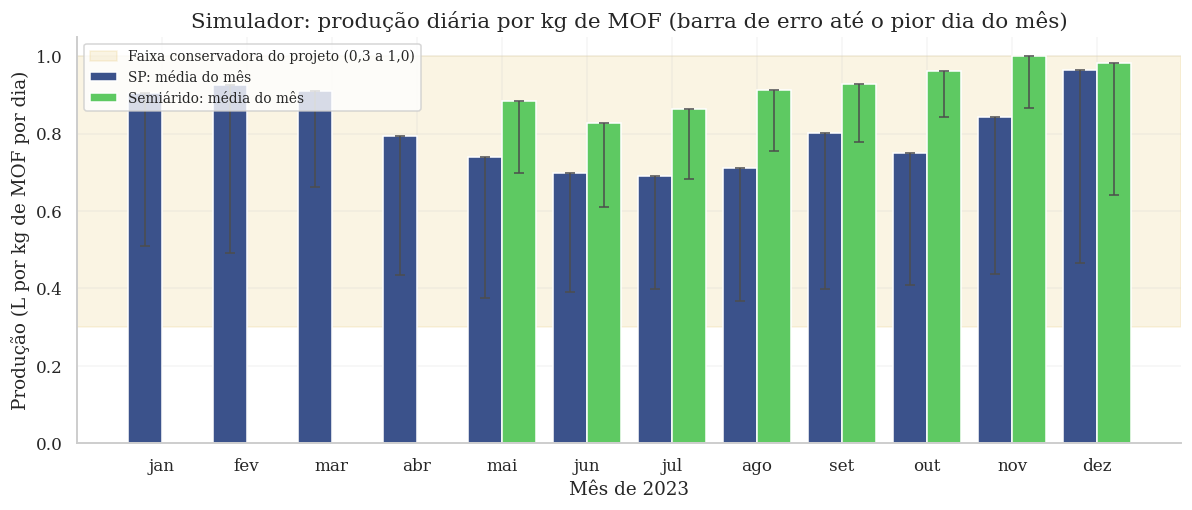

In [15]:
# produção média mensal e pior dia
fig, ax = plt.subplots(figsize=(11, 4.8))
largura = 0.4
for i, (terr, m) in enumerate(mensal.items()):
    pos = np.array(m.index) + (i - 0.5) * largura
    ax.bar(pos, m["media"], width=largura, color=COR[terr], label=f"{terr}: média do mês", zorder=2)
    ax.errorbar(pos, m["media"], yerr=[m["media"] - m["minimo"], np.zeros(len(m))], fmt="none",
                ecolor="0.3", capsize=3, lw=1, zorder=3)
ax.axhspan(0.3, 1.0, color="goldenrod", alpha=0.12, zorder=0,
           label="Faixa conservadora do projeto (0,3 a 1,0)")
ax.set(xticks=range(1, 13), xticklabels=NOMES_MES[1:], xlabel="Mês de 2023",
       ylabel="Produção (L por kg de MOF por dia)",
       title="Simulador: produção diária por kg de MOF (barra de erro até o pior dia do mês)")
ax.legend(loc="upper left", fontsize=9)
salvar(fig, "04_simulador_mensal")

## 5. Dia típico do mês crítico
### 5.1 Regressão harmônica (ML)

In [16]:
def matriz_harmonica(t, K):
    # colunas: 1, cos(2πkt/24), sin(2πkt/24) para k = 1..K
    t = np.asarray(t, dtype=float)
    colunas = [np.ones_like(t)]
    for k in range(1, K + 1):
        colunas += [np.cos(2 * np.pi * k * t / 24), np.sin(2 * np.pi * k * t / 24)]
    return np.column_stack(colunas)


def minimos_quadrados(X, y):
    # equação normal: (XᵀX) β = Xᵀy
    return np.linalg.solve(X.T @ X, X.T @ y)


def r2_manual(y, y_hat):
    return 1 - np.sum((y - y_hat) ** 2) / np.sum((y - np.mean(y)) ** 2)


def rmse_manual(y, y_hat):
    return np.sqrt(np.mean((y - y_hat) ** 2))


def amostra_mes(df, mes):
    completos = dias_completos(df)
    sel = df[(df.index.month == mes) & df.index.normalize().isin(completos)].copy()
    sel["t"] = sel.index.hour
    sel["dia_mes"] = sel.index.day
    return sel


def comparar_modelos(sel, var):
    # treino: dias 1 a 21 | teste: dias seguintes
    treino, teste = sel[sel["dia_mes"] <= 21], sel[sel["dia_mes"] > 21]
    resultados, ajustes = [], {}
    for K in [1, 2, 3]:
        beta = minimos_quadrados(matriz_harmonica(treino["t"], K), treino[var].to_numpy())
        ajustes[f"harmônico K={K}"] = beta
        resultados.append((f"harmônico K={K}", 2 * K + 1, matriz_harmonica(teste["t"], K) @ beta))
    poli = np.polyfit(treino["t"], treino[var], 3)
    ajustes["polinômio grau 3"] = poli
    resultados.append(("polinômio grau 3", 4, np.polyval(poli, teste["t"])))
    media_hora = treino.groupby("t")[var].mean()
    resultados.append(("média por hora", 24, teste["t"].map(media_hora).to_numpy()))

    y = teste[var].to_numpy()
    tab = pd.DataFrame([{
        "modelo": nome, "parâmetros": n_par,
        "R² teste": r2_manual(y, prev), "RMSE teste": rmse_manual(y, prev),
    } for nome, n_par, prev in resultados]).set_index("modelo")
    return tab, ajustes, treino, teste


modelos_dia = {}
for terr, df in clima.items():
    mes = MES_CRITICO[terr]
    sel = amostra_mes(df, mes)
    tab_ur, aj_ur, treino, teste = comparar_modelos(sel, "ur")
    tab_t, aj_t, _, _ = comparar_modelos(sel, "temp")
    modelos_dia[terr] = {"sel": sel, "treino": treino, "teste": teste,
                         "beta_ur": aj_ur["harmônico K=2"], "beta_t": aj_t["harmônico K=2"],
                         "poli_ur": aj_ur["polinômio grau 3"]}
    print(f"\n{terr} · {NOMES_MES[mes]}/2023 · treino: {treino['dia_mes'].nunique()} dias, "
          f"teste: {teste['dia_mes'].nunique()} dias")
    print("Umidade (RMSE em p.p.):")
    tabela(tab_ur)
    print("Temperatura (RMSE em °C):")
    tabela(tab_t)


SP · jul/2023 · treino: 16 dias, teste: 9 dias
Umidade (RMSE em p.p.):


,parâmetros,R² teste,RMSE teste
modelo,,,
harmônico K=1,3,0.4637,12.6386
harmônico K=2,5,0.5243,11.9040
harmônico K=3,7,0.5225,11.9264
polinômio grau 3,4,0.4188,13.1574
média por hora,24,0.5209,11.9454


Temperatura (RMSE em °C):


,parâmetros,R² teste,RMSE teste
modelo,,,
harmônico K=1,3,0.4166,2.9221
harmônico K=2,5,0.4767,2.7675
harmônico K=3,7,0.4764,2.7682
polinômio grau 3,4,0.3661,3.0460
média por hora,24,0.4772,2.7661



Semiárido · jun/2023 · treino: 21 dias, teste: 9 dias
Umidade (RMSE em p.p.):


,parâmetros,R² teste,RMSE teste
modelo,,,
harmônico K=1,3,0.7345,7.6730
harmônico K=2,5,0.7624,7.2584
harmônico K=3,7,0.7645,7.2265
polinômio grau 3,4,0.6864,8.3391
média por hora,24,0.7647,7.2242


Temperatura (RMSE em °C):


,parâmetros,R² teste,RMSE teste
modelo,,,
harmônico K=1,3,0.7423,1.5731
harmônico K=2,5,0.7836,1.4416
harmônico K=3,7,0.7841,1.4399
polinômio grau 3,4,0.6839,1.7423
média por hora,24,0.7846,1.4383


In [17]:
# conferência com scikit-learn
for terr, md in modelos_dia.items():
    reg = LinearRegression(fit_intercept=False).fit(matriz_harmonica(md["treino"]["t"], 2), md["treino"]["ur"])
    prev = matriz_harmonica(md["teste"]["t"], 2) @ md["beta_ur"]
    y_te = md["teste"]["ur"].to_numpy()
    print(f"{terr}: diferença máx. dos coeficientes = {np.max(np.abs(reg.coef_ - md['beta_ur'])):.2e} | "
          f"R² {r2_manual(y_te, prev):.6f} x {r2_score(y_te, prev):.6f} | "
          f"RMSE {rmse_manual(y_te, prev):.6f} x {np.sqrt(mean_squared_error(y_te, prev)):.6f}")

SP: diferença máx. dos coeficientes = 2.84e-14 | R² 0.524256 x 0.524256 | RMSE 11.903971 x 11.903971
Semiárido: diferença máx. dos coeficientes = 1.42e-14 | R² 0.762423 x 0.762423 | RMSE 7.258421 x 7.258421


### 5.2 Equações, resíduos e continuidade à meia-noite

SP: u(t) = 68.557 +11.212·cos(πt/12) +13.135·sin(πt/12) -3.962·cos(πt/6) -4.123·sin(πt/6)   [%]
    T(t) = 17.236 -2.466·cos(πt/12) -2.555·sin(πt/12) +0.938·cos(πt/6) +0.964·sin(πt/6)   [°C]
Semiárido: u(t) = 67.198 +12.485·cos(πt/12) +13.170·sin(πt/12) -3.053·cos(πt/6) -1.353·sin(πt/6)   [%]
           T(t) = 25.217 -2.636·cos(πt/12) -2.572·sin(πt/12) +0.680·cos(πt/6) +0.476·sin(πt/6)   [°C]


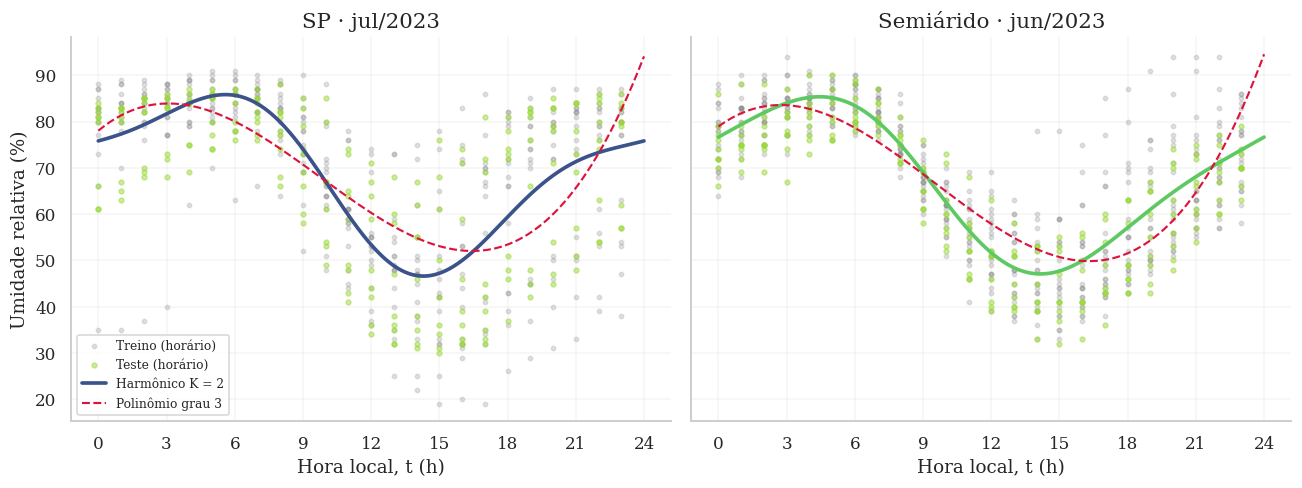

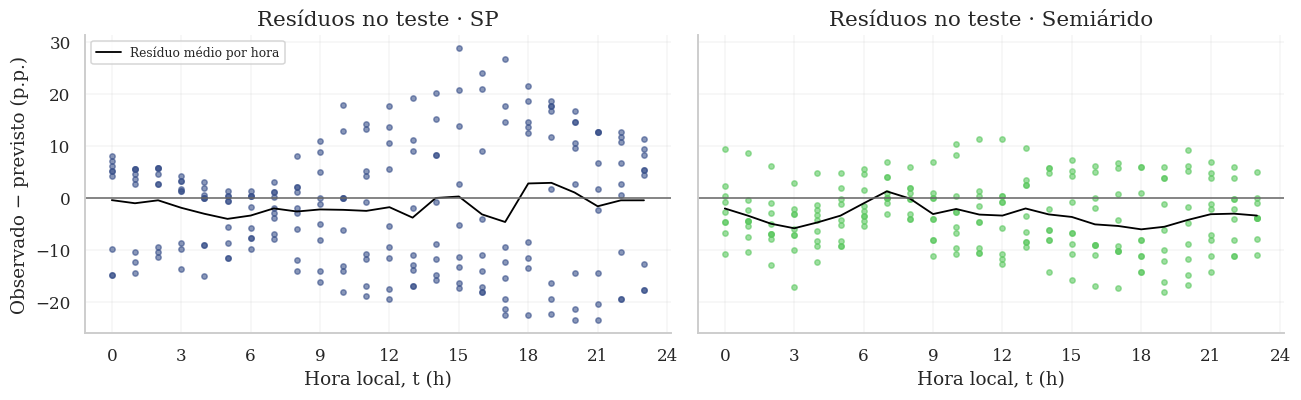

In [18]:
def u_mod(t, terr):
    return matriz_harmonica(np.atleast_1d(t), 2) @ modelos_dia[terr]["beta_ur"]


def T_mod(t, terr):
    return matriz_harmonica(np.atleast_1d(t), 2) @ modelos_dia[terr]["beta_t"]


for terr, md in modelos_dia.items():
    b0, a1, b1, a2, b2 = md["beta_ur"]
    print(f"{terr}: u(t) = {b0:.3f} {a1:+.3f}·cos(πt/12) {b1:+.3f}·sin(πt/12) "
          f"{a2:+.3f}·cos(πt/6) {b2:+.3f}·sin(πt/6)   [%]")
    c0, c1, d1, c2, d2 = md["beta_t"]
    print(f"{' ' * len(terr)}  T(t) = {c0:.3f} {c1:+.3f}·cos(πt/12) {d1:+.3f}·sin(πt/12) "
          f"{c2:+.3f}·cos(πt/6) {d2:+.3f}·sin(πt/6)   [°C]")

# dados x modelos
t_fino = np.linspace(0, 24, 481)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for (terr, md), ax in zip(modelos_dia.items(), eixos):
    ax.scatter(md["treino"]["t"], md["treino"]["ur"], s=8, alpha=0.25, color="0.55", label="Treino (horário)")
    ax.scatter(md["teste"]["t"], md["teste"]["ur"], s=10, alpha=0.5, color=VIRIDIS(0.85), label="Teste (horário)")
    ax.plot(t_fino, u_mod(t_fino, terr), color=COR[terr], lw=2.4, label="Harmônico K = 2")
    ax.plot(t_fino, np.polyval(md["poli_ur"], t_fino), color="crimson", lw=1.4, ls="--", label="Polinômio grau 3")
    ax.set(xlabel="Hora local, t (h)", title=f"{terr} · {NOMES_MES[MES_CRITICO[terr]]}/2023",
           xticks=range(0, 25, 3))
eixos[0].set_ylabel("Umidade relativa (%)")
eixos[0].legend(fontsize=8)
salvar(fig, "05_regressao_umidade")

# resíduos no teste
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for (terr, md), ax in zip(modelos_dia.items(), eixos):
    res = md["teste"]["ur"] - u_mod(md["teste"]["t"].to_numpy(), terr)
    ax.scatter(md["teste"]["t"], res, s=12, color=COR[terr], alpha=0.6)
    medio = res.groupby(md["teste"]["t"]).mean()
    ax.plot(medio.index, medio.values, color="k", lw=1.2, label="Resíduo médio por hora")
    ax.axhline(0, color="0.4", lw=1)
    ax.set(xlabel="Hora local, t (h)", title=f"Resíduos no teste · {terr}", xticks=range(0, 25, 3))
eixos[0].set_ylabel("Observado − previsto (p.p.)")
eixos[0].legend(fontsize=8)
salvar(fig, "06_residuos")

SP: u(24⁻) − u(0)  harmônico = -1.28e-09 p.p. | polinômio = +16.07 p.p. | salto de u' no polinômio = +8.59 p.p./h
Semiárido: u(24⁻) − u(0)  harmônico = -2.74e-09 p.p. | polinômio = +15.62 p.p. | salto de u' no polinômio = +9.61 p.p./h


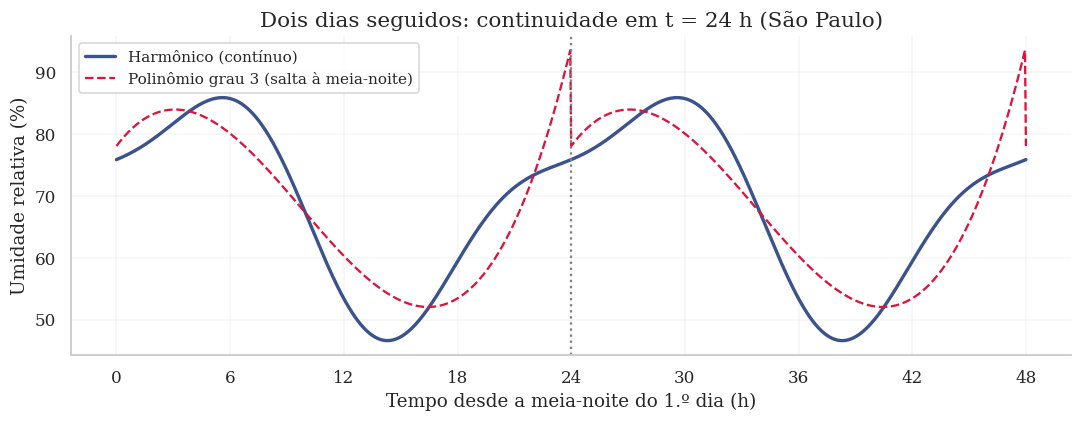

In [19]:
# continuidade em t = 24: harmônico x polinômio
for terr, md in modelos_dia.items():
    poli = md["poli_ur"]
    dpoli = np.polyder(poli)
    salto_h = float(u_mod(24 - 1e-9, terr)[0] - u_mod(0, terr)[0])
    salto_p = np.polyval(poli, 24) - np.polyval(poli, 0)
    print(f"{terr}: u(24⁻) − u(0)  harmônico = {salto_h:+.2e} p.p. | polinômio = {salto_p:+.2f} p.p. | "
          f"salto de u' no polinômio = {np.polyval(dpoli, 24) - np.polyval(dpoli, 0):+.2f} p.p./h")

dois_dias = np.linspace(0, 48, 961)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dois_dias, u_mod(dois_dias % 24, "SP"), color=COR["SP"], lw=2.2, label="Harmônico (contínuo)")
ax.plot(dois_dias, np.polyval(modelos_dia["SP"]["poli_ur"], dois_dias % 24), color="crimson", lw=1.5,
        ls="--", label="Polinômio grau 3 (salta à meia-noite)")
ax.axvline(24, color="0.5", ls=":")
ax.set(xlabel="Tempo desde a meia-noite do 1.º dia (h)", ylabel="Umidade relativa (%)",
       title="Dois dias seguidos: continuidade em t = 24 h (São Paulo)", xticks=range(0, 49, 6))
ax.legend()
salvar(fig, "07_continuidade_meia_noite")

### 5.3 Derivada da umidade e pontos críticos

In [20]:
# u'(t) à mão x SymPy
t_s = sp.symbols("t", real=True)
omega = sp.pi / 12
derivadas = {}
for terr, md in modelos_dia.items():
    b0, a1, b1, a2, b2 = [sp.Float(v, 12) for v in md["beta_ur"]]
    u_expr = (b0 + a1 * sp.cos(omega * t_s) + b1 * sp.sin(omega * t_s)
              + a2 * sp.cos(2 * omega * t_s) + b2 * sp.sin(2 * omega * t_s))
    du_manual = (omega * (-a1 * sp.sin(omega * t_s) + b1 * sp.cos(omega * t_s))
                 + 2 * omega * (-a2 * sp.sin(2 * omega * t_s) + b2 * sp.cos(2 * omega * t_s)))
    print(f"{terr}: u' manual − u' SymPy = {sp.simplify(sp.diff(u_expr, t_s) - du_manual)}")
    derivadas[terr] = {
        "u": sp.lambdify(t_s, u_expr, "numpy"),
        "du": sp.lambdify(t_s, du_manual, "numpy"),
        "d2u": sp.lambdify(t_s, sp.diff(u_expr, t_s, 2), "numpy"),
        "expr": u_expr,
    }

# derivada pela definição (h → 0) em t0 = 9 h
t0 = 9.0
fu, fdu = derivadas["SP"]["u"], derivadas["SP"]["du"]
tabela(pd.DataFrame([{"h (h)": h, "[u(t0+h) − u(t0)]/h": (fu(t0 + h) - fu(t0)) / h,
                      "erro": (fu(t0 + h) - fu(t0)) / h - fdu(t0)}
                     for h in [1, 0.1, 0.01, 0.001, 1e-4, 1e-5]]))
print(f"u'(9) pela fórmula = {fdu(t0):.6f} %/h")

SP: u' manual − u' SymPy = pi*(1.51582450295e-13*sin(pi*t/12) - 7.57912251477e-14*sin(pi*t/6))


Semiárido: u' manual − u' SymPy = pi*(1.51582450295e-13*sin(pi*t/12) - 7.57912251477e-14*sin(pi*t/6))


,h (h),[u(t0+h) − u(t0)]/h,erro
0,1.0000,-7.0355,-0.4539
1,0.1000,-6.6412,-0.0597
2,0.0100,-6.5876,-0.0061
3,0.0010,-6.5821,-0.0006
4,0.0001,-6.5816,-0.0001
5,0.0000,-6.5815,-0.0000


u'(9) pela fórmula = -6.581533 %/h


,território,t (h),hora,u (%),u' (%/h),u'' (%/h²),tipo
0,SP,5.5907,05h35,85.8105,-0.0000,-1.7982,máximo local
1,SP,14.3033,14h18,46.6082,-0.0000,2.5870,mínimo local
2,SP,10.2001,10h12,65.5370,-7.3438,0.0000,queda mais rápida (u'' = 0)
3,Semiárido,4.4534,04h27,85.3476,0.0000,-1.4754,máximo local
4,Semiárido,14.1680,14h10,47.0761,0.0000,1.8962,mínimo local
5,Semiárido,9.5154,09h31,65.7284,-6.4526,-0.0000,queda mais rápida (u'' = 0)


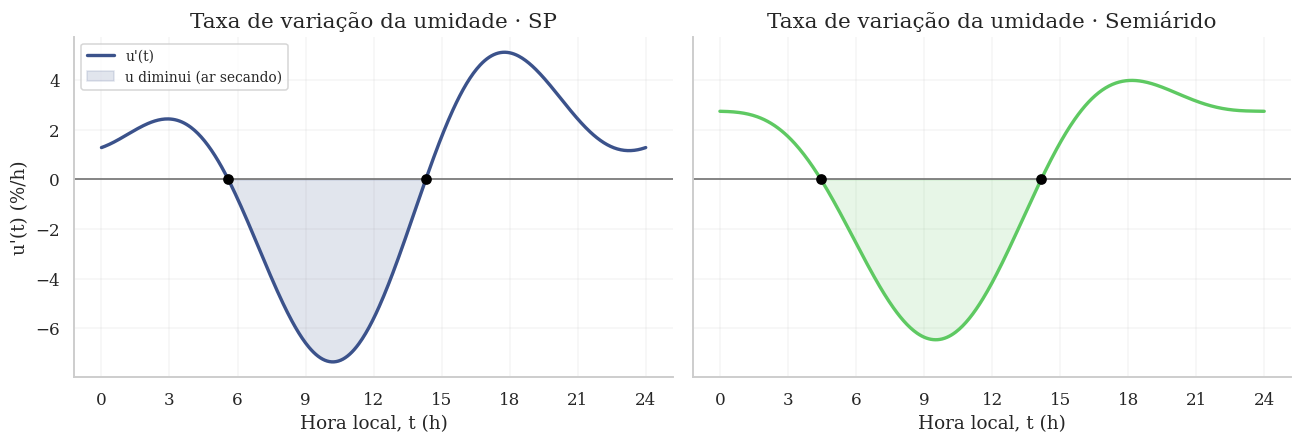

In [21]:
# pontos críticos (u' = 0) e queda mais rápida (u'' = 0)
def raizes(f, a=0.0, b=24.0, n=2401):
    malha = np.linspace(a, b, n)
    valores = f(malha)
    return [brentq(f, malha[i], malha[i + 1]) for i in range(n - 1) if valores[i] * valores[i + 1] < 0]


def hora_txt(t):
    minutos = int(round(60 * t))
    return f"{minutos // 60:02d}h{minutos % 60:02d}"


criticos = []
for terr, d in derivadas.items():
    pontos = [(tc, "máximo local" if d["d2u"](tc) < 0 else "mínimo local") for tc in raizes(d["du"])]
    pontos.append((min(raizes(d["d2u"]), key=d["du"]), "queda mais rápida (u'' = 0)"))
    for tc, tipo in pontos:
        criticos.append({"território": terr, "t (h)": tc, "hora": hora_txt(tc), "u (%)": d["u"](tc),
                         "u' (%/h)": d["du"](tc), "u'' (%/h²)": d["d2u"](tc), "tipo": tipo})
tabela(pd.DataFrame(criticos))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for (terr, d), ax in zip(derivadas.items(), eixos):
    ax.plot(t_fino, d["du"](t_fino), color=COR[terr], lw=2.2, label="u'(t)")
    ax.axhline(0, color="0.4", lw=1)
    ax.fill_between(t_fino, d["du"](t_fino), 0, where=d["du"](t_fino) < 0, color=COR[terr], alpha=0.15,
                    label="u diminui (ar secando)")
    for tc in raizes(d["du"]):
        ax.scatter([tc], [0], color="k", zorder=5)
    ax.set(xlabel="Hora local, t (h)", title=f"Taxa de variação da umidade · {terr}", xticks=range(0, 25, 3))
eixos[0].set_ylabel("u'(t) (%/h)")
eixos[0].legend(fontsize=9)
salvar(fig, "08_derivada_umidade")

### 5.4 Valor médio da umidade pela integral

In [22]:
for terr, d in derivadas.items():
    md = modelos_dia[terr]
    integral_sym = sp.integrate(d["expr"], (t_s, 0, 24))
    integral_quad, _ = quad(d["u"], 0, 24)
    perfil = md["treino"].groupby("t")["ur"].mean()
    t_perfil = np.append(perfil.index.to_numpy(), 24)
    y_perfil = np.append(perfil.to_numpy(), perfil.iloc[0])
    print(f"{terr}: β0 = {md['beta_ur'][0]:.4f} | simbólico = {float(integral_sym) / 24:.4f} | "
          f"quad = {integral_quad / 24:.4f} | trapézios = {trapezoid(y_perfil, t_perfil) / 24:.4f} | "
          f"média do treino = {md['treino']['ur'].mean():.4f} %")

SP: β0 = 68.5573 | simbólico = 68.5573 | quad = 68.5573 | trapézios = 68.5573 | média do treino = 68.5573 %


Semiárido: β0 = 67.1984 | simbólico = 67.1984 | quad = 67.1984 | trapézios = 67.1984 | média do treino = 67.1984 %


### 5.5 Irradiância (meio seno) e energia diária

In [23]:
def G_meio_seno(t, G_max, t_n, t_p):
    t = np.asarray(t, dtype=float)
    fase = np.clip((t - t_n) / (t_p - t_n), 0, 1)
    return G_max * np.sin(np.pi * fase)


modelo_G = {}
for terr, md in modelos_dia.items():
    sel = md["sel"]
    perfil = sel.groupby(sel.index.hour)["G"].mean()
    t_centro = perfil.index.to_numpy() - 0.5  # meio da hora a que o registro se refere
    (G_max, t_n, t_p), _ = curve_fit(G_meio_seno, t_centro, perfil.to_numpy(), p0=[800, 6, 18])
    modelo_G[terr] = (G_max, t_n, t_p)
    E_analitica = 2 * G_max * (t_p - t_n) / np.pi
    E_quad, _ = quad(G_meio_seno, t_n, t_p, args=(G_max, t_n, t_p))
    E_dados = sel.groupby(sel.index.normalize())["rad_kj"].sum().mean() / 3.6
    print(f"{terr}: G_max = {G_max:.1f} W/m², nascer = {t_n:.2f} h, pôr = {t_p:.2f} h | "
          f"E analítica = {E_analitica:.0f} | quad = {E_quad:.0f} | dados = {E_dados:.0f} Wh/m² | "
          f"erro = {100 * (E_analitica / E_dados - 1):+.1f} %")

SP: G_max = 689.0 W/m², nascer = 7.26 h, pôr = 16.76 h | E analítica = 4169 | quad = 4169 | dados = 4187 Wh/m² | erro = -0.4 %
Semiárido: G_max = 588.1 W/m², nascer = 6.17 h, pôr = 17.17 h | E analítica = 4119 | quad = 4119 | dados = 4137 Wh/m² | erro = -0.4 %


### 5.6 Produção no dia típico e integração numérica

In [24]:
def p_tipico(t, terr):
    # p(t) = R*(u(t), T(t)) · f(G(t))
    escalar = np.ndim(t) == 0
    t = np.atleast_1d(np.asarray(t, dtype=float))
    ciclo = ciclo_otimo(u_mod(t, terr), T_mod(t, terr))
    p = ciclo["R"] * fator_climatico(G_meio_seno(t, *modelo_G[terr]))
    return float(p[0]) if escalar else p


def bicos(terr):
    # instantes em que G = G_NOITE ou G = G_REF (f não é derivável)
    G_max, t_n, t_p = modelo_G[terr]
    pts = []
    for G_alvo in [G_NOITE, G_REF]:
        if G_alvo < G_max:
            s = np.arcsin(G_alvo / G_max) / np.pi
            pts += [t_n + s * (t_p - t_n), t_p - s * (t_p - t_n)]
    return sorted(pts)


def riemann(f, a, b, n, regra):
    x = np.linspace(a, b, n + 1)
    dx = (b - a) / n
    if regra == "esquerda":
        return np.sum(f(x[:-1])) * dx
    if regra == "direita":
        return np.sum(f(x[1:])) * dx
    return np.sum(f((x[:-1] + x[1:]) / 2)) * dx


def simpson_por_partes(f, pontos, n_total):
    # Simpson em cada trecho suave entre dois bicos
    total = 0.0
    for a, b in zip(pontos[:-1], pontos[1:]):
        n = max(2, int(round(n_total * (b - a) / (pontos[-1] - pontos[0]) / 2)) * 2)
        x = np.linspace(a, b, n + 1)
        total += simpson(f(x), x=x)
    return total


tipico, erros_integral = {}, {}
for terr in modelos_dia:
    f_p = lambda t, terr=terr: p_tipico(t, terr)
    referencia, _ = quad(f_p, 0, 24, points=bicos(terr), limit=200)
    linhas = []
    for n in [6, 12, 24, 48, 96, 192, 384, 768]:
        x = np.linspace(0, 24, n + 1)
        y = f_p(x)
        linhas.append({"n": n,
                       "Riemann esq.": riemann(f_p, 0, 24, n, "esquerda") - referencia,
                       "Riemann dir.": riemann(f_p, 0, 24, n, "direita") - referencia,
                       "ponto médio": riemann(f_p, 0, 24, n, "medio") - referencia,
                       "trapézios": trapezoid(y, x) - referencia,
                       "Simpson": simpson(y, x=x) - referencia,
                       "Simpson por partes": simpson_por_partes(f_p, bicos(terr), n) - referencia})
    erros = pd.DataFrame(linhas).set_index("n")
    erros_integral[terr] = erros
    print(f"\n{terr}: ∫ p dt (quad) = {referencia:.6f} L/kg. Erro de cada método:")
    tabela(erros.map(lambda v: f"{v:+.2e}"))

    # máximo de p(t) e lote noturno do dia típico
    t_malha = np.linspace(0, 24, 4801)
    p_malha = f_p(t_malha)
    i_max = int(np.argmax(p_malha))
    noite = (t_malha < modelo_G[terr][1]) | (t_malha > modelo_G[terr][2])
    H_noite = 24 - (bicos(terr)[-1] - bicos(terr)[0])
    lote = float(lote_noturno(np.mean(u_mod(t_malha[noite], terr)), np.mean(T_mod(t_malha[noite], terr)),
                              H_noite))
    tipico[terr] = {"integral": referencia, "lote": lote, "total": referencia + lote,
                    "t_max": t_malha[i_max], "p_max": p_malha[i_max], "t": t_malha, "p": p_malha}


SP: ∫ p dt (quad) = 0.385633 L/kg. Erro de cada método:


,Riemann esq.,Riemann dir.,ponto médio,trapézios,Simpson,Simpson por partes
n,,,,,,
6,-3.94e-02,-3.94e-02,+4.66e-02,-3.94e-02,+5.97e-03,+8.18e-05
12,+3.60e-03,+3.60e-03,-1.40e-03,+3.60e-03,+1.79e-02,+4.71e-06
24,+1.10e-03,+1.10e-03,-2.02e-03,+1.10e-03,+2.70e-04,+2.93e-07
48,-4.57e-04,-4.57e-04,+2.81e-04,-4.57e-04,-9.77e-04,+1.83e-08
96,-8.80e-05,-8.80e-05,+7.63e-05,-8.80e-05,+3.51e-05,+1.14e-09
192,-5.86e-06,-5.86e-06,+2.35e-05,-5.86e-06,+2.15e-05,+7.04e-11
384,+8.82e-06,+8.82e-06,-6.59e-06,+8.82e-06,+1.37e-05,+4.65e-12
768,+1.11e-06,+1.11e-06,+2.91e-07,+1.11e-06,-1.46e-06,+2.91e-13



Semiárido: ∫ p dt (quad) = 0.526223 L/kg. Erro de cada método:


,Riemann esq.,Riemann dir.,ponto médio,trapézios,Simpson,Simpson por partes
n,,,,,,
6,+1.63e-02,+1.63e-02,-7.40e-03,+1.63e-02,+4.31e-02,+2.27e-04
12,+4.46e-03,+4.46e-03,-3.67e-03,+4.46e-03,+5.09e-04,+1.31e-05
24,+3.98e-04,+3.98e-04,-8.91e-04,+3.98e-04,-9.57e-04,+8.09e-07
48,-2.47e-04,-2.47e-04,+2.99e-04,-2.47e-04,-4.61e-04,+5.05e-08
96,+2.62e-05,+2.62e-05,-5.96e-05,+2.62e-05,+1.17e-04,+3.15e-09
192,-1.67e-05,-1.67e-05,+1.64e-05,-1.67e-05,-3.10e-05,+1.97e-10
384,-1.70e-07,-1.70e-07,-1.84e-06,-1.70e-07,+5.34e-06,+1.23e-11
768,-1.01e-06,-1.01e-06,+1.48e-06,-1.01e-06,-1.29e-06,+7.70e-13


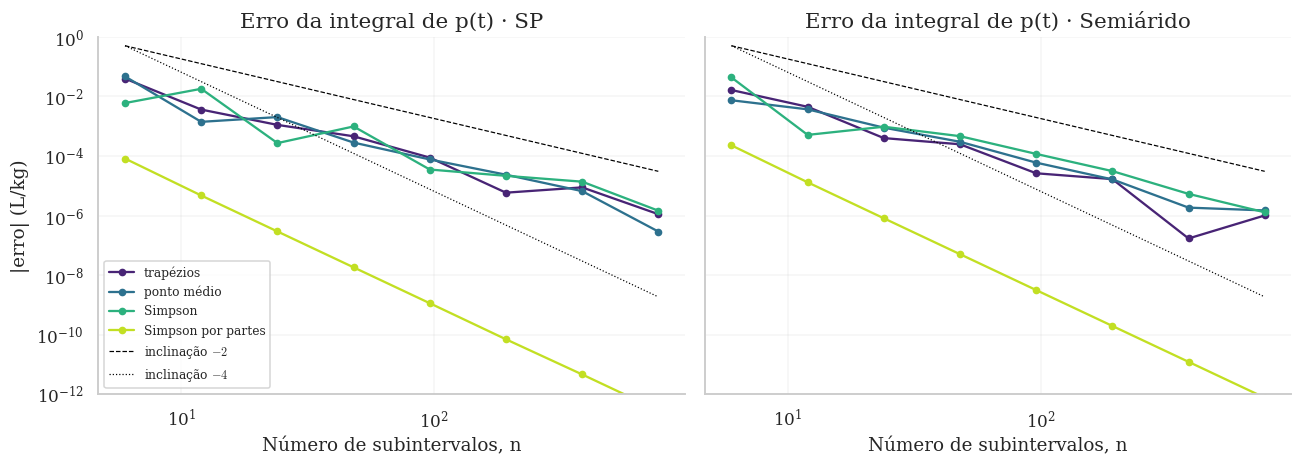

In [25]:
# convergência dos métodos (log-log)
n_ref = np.array([6, 768])
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for (terr, erros), ax in zip(erros_integral.items(), eixos):
    for i, metodo in enumerate(["trapézios", "ponto médio", "Simpson", "Simpson por partes"]):
        ax.loglog(erros.index, np.abs(erros[metodo]) + 1e-16, "o-", ms=4, lw=1.5,
                  color=VIRIDIS(0.1 + 0.27 * i), label=metodo)
    ax.loglog(n_ref, 0.5 * (n_ref / 6.0) ** -2, "k--", lw=0.8, label=r"inclinação $-2$")
    ax.loglog(n_ref, 0.5 * (n_ref / 6.0) ** -4, "k:", lw=0.8, label=r"inclinação $-4$")
    ax.set(xlabel="Número de subintervalos, n", title=f"Erro da integral de p(t) · {terr}", ylim=(1e-12, 1))
eixos[0].set_ylabel("|erro| (L/kg)")
eixos[0].legend(fontsize=8)
salvar(fig, "09a_convergencia_integral")

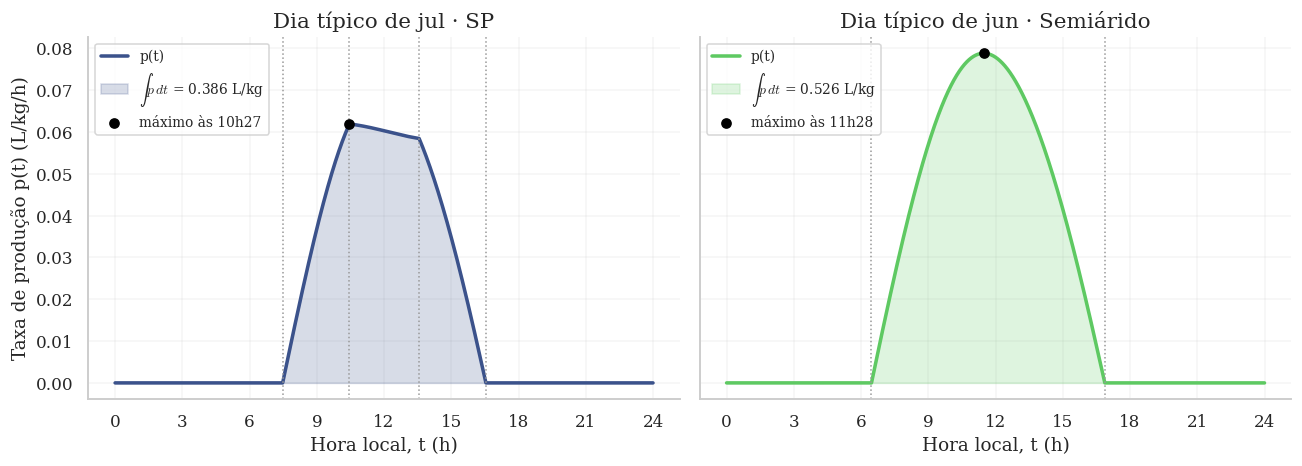

,SP,Semiárido
∫ p dt (L/kg),0.3856,0.5262
lote noturno (L/kg),0.3477,0.3489
total dia típico (L/kg/dia),0.7334,0.8751
média real do mês (L/kg/dia),0.6908,0.8276
diferença (%),6.1588,5.7332
pessoas-dia por kg (2 L/pessoa),0.3667,0.4375


,SP,Semiárido
∫ p dt (L/kg),0.3856,0.5262
lote noturno (L/kg),0.3477,0.3489
total dia típico (L/kg/dia),0.7334,0.8751
média real do mês (L/kg/dia),0.6908,0.8276
diferença (%),6.1588,5.7332
pessoas-dia por kg (2 L/pessoa),0.3667,0.4375


In [26]:
# p(t) no dia típico
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for (terr, tp), ax in zip(tipico.items(), eixos):
    ax.plot(tp["t"], tp["p"], color=COR[terr], lw=2.3, label="p(t)")
    ax.fill_between(tp["t"], tp["p"], color=COR[terr], alpha=0.2,
                    label=rf"$\int p\,dt$ = {tp['integral']:.3f} L/kg")
    ax.scatter([tp["t_max"]], [tp["p_max"]], color="k", zorder=5, label=f"máximo às {hora_txt(tp['t_max'])}")
    for b in bicos(terr):
        ax.axvline(b, color="0.6", ls=":", lw=1)
    ax.set(xlabel="Hora local, t (h)", title=f"Dia típico de {NOMES_MES[MES_CRITICO[terr]]} · {terr}",
           xticks=range(0, 25, 3))
    ax.legend(fontsize=9, loc="upper left")
eixos[0].set_ylabel("Taxa de produção p(t) (L/kg/h)")
salvar(fig, "09_producao_dia_tipico")

# dia típico x média real do mês
tabela(pd.DataFrame({
    terr: {"∫ p dt (L/kg)": tp["integral"], "lote noturno (L/kg)": tp["lote"],
           "total dia típico (L/kg/dia)": tp["total"],
           "média real do mês (L/kg/dia)": mensal[terr].loc[MES_CRITICO[terr], "media"],
           "diferença (%)": 100 * (tp["total"] / mensal[terr].loc[MES_CRITICO[terr], "media"] - 1),
           "pessoas-dia por kg (2 L/pessoa)": tp["total"] / 2}
    for terr, tp in tipico.items()}))

## 6. Reservatório e massa mínima de MOF

In [27]:
N_PESSOAS = 25
V_MIN = 5.0     # L, abaixo disso: "Sem água"
DT = 0.05       # h (3 min)


def capacidade(n_pessoas):
    # dois dias de demanda
    return 4.0 * n_pessoas


def demanda(t_dia, n_pessoas):
    # duas gaussianas (10 h e 15 h); integral diária = 2 L por pessoa
    gauss = lambda mu: np.exp(-0.5 * ((t_dia - mu) / 1.5) ** 2) / (1.5 * np.sqrt(2 * np.pi))
    return 2 * n_pessoas * 0.5 * (gauss(10.0) + gauss(15.0))


def serie_fina(terr):
    # produção por kg em passos de DT, com os dias completos do mês crítico em ordem
    d = hora_a_hora[terr]
    dd = diaria[terr]
    seq = dd.index[dd.index.month == MES_CRITICO[terr]].sort_values()
    d = d[d["dia"].isin(seq)]
    p_h = d["p"].to_numpy().copy()
    for dia in seq:  # lote noturno sai na primeira hora de sol
        idx = np.where((d["dia"] == dia).to_numpy() & ~d["noite"].to_numpy())[0]
        if len(idx):
            p_h[idx[0]] += dd.loc[dia, "lote"]
    p_fino = np.repeat(p_h, int(round(1 / DT)))
    t_fino_ = np.arange(len(p_fino)) * DT + DT / 2
    return t_fino_, p_fino, seq


def simular(m, p_fino, c_fino, cap):
    # V(t) = V0 + ∫(m·p − c) dt, passo a passo, limitado pela capacidade
    V = np.empty(len(p_fino) + 1)
    V[0] = cap / 2
    for i in range(len(p_fino)):
        V[i + 1] = min(cap, V[i] + (m * p_fino[i] - c_fino[i]) * DT)
    return V


def folga(m, p_fino, c_fino, cap):
    # > 0 quando as duas condições valem: V nunca abaixo de V_MIN e V(fim) >= V(0)
    V = simular(m, p_fino, c_fino, cap)
    return min(V.min() - V_MIN, V[-1] - V[0])


def massa_minima(p_fino, c_fino, cap, m_max=1000.0):
    # menor m com folga = 0 (método de Brent); inf se nem m_max resolve
    if folga(m_max, p_fino, c_fino, cap) < 0:
        return np.inf
    return brentq(folga, 0.0, m_max, args=(p_fino, c_fino, cap), xtol=1e-4)


t_dia_fino = np.linspace(0, 24, 2401)
print(f"∫ c(t) dt em um dia = {trapezoid(demanda(t_dia_fino, N_PESSOAS), t_dia_fino):.4f} L")

reservatorio = {}
cap = capacidade(N_PESSOAS)
for terr in clima:
    t_f, p_f, seq = serie_fina(terr)
    c_f = demanda(t_f % 24, N_PESSOAS)
    m_star = massa_minima(p_f, c_f, cap)
    m_lim = c_f.mean() / p_f.mean()  # piso vindo do limite no infinito
    reservatorio[terr] = {"t": t_f, "p": p_f, "c": c_f, "seq": seq, "m_star": m_star, "m_lim": m_lim,
                          "V": simular(m_star, p_f, c_f, cap)}
    V_50 = simular(50.0, p_f, c_f, cap)
    print(f"{terr}: {len(seq)} dias | m_lim = {m_lim:.1f} kg | m* = {m_star:.1f} kg | "
          f"com 50 kg fica sem água no dia {np.argmax(V_50 < V_MIN) * DT / 24:.2f}")

∫ c(t) dt em um dia = 50.0000 L


SP: 25 dias | m_lim = 72.4 kg | m* = 72.4 kg | com 50 kg fica sem água no dia 2.74


Semiárido: 30 dias | m_lim = 60.4 kg | m* = 60.4 kg | com 50 kg fica sem água no dia 4.65


In [28]:
# V(t)/t → m·p̄ − c̄ (dia típico repetido, 50 kg, sem limite de capacidade)
m_teste = 50.0
t_dia = np.arange(0, 24, DT) + DT / 2
for terr in clima:
    p_dia = p_tipico(t_dia, terr)
    p_dia[np.argmax(fator_climatico(G_meio_seno(t_dia, *modelo_G[terr])) > 0)] += tipico[terr]["lote"] / DT
    c_dia = demanda(t_dia, N_PESSOAS)
    linhas = []
    for dias in [1, 10, 100, 1000]:
        V_fim = capacidade(N_PESSOAS) / 2 + np.sum(np.tile(m_teste * p_dia - c_dia, dias)) * DT
        linhas.append({"dias": dias, "t (h)": 24 * dias, "V(t)/t (L/h)": V_fim / (24 * dias)})
    print(f"{terr}: m·p̄ − c̄ = {np.mean(m_teste * p_dia - c_dia):+.4f} L/h")
    tabela(pd.DataFrame(linhas))

SP: m·p̄ − c̄ = -0.5555 L/h


,dias,t (h),V(t)/t (L/h)
0,1,24,1.5278
1,10,240,-0.3472
2,100,2400,-0.5347
3,1000,24000,-0.5534


Semiárido: m·p̄ − c̄ = -0.2602 L/h


,dias,t (h),V(t)/t (L/h)
0,1,24,1.8231
1,10,240,-0.0519
2,100,2400,-0.2394
3,1000,24000,-0.2582


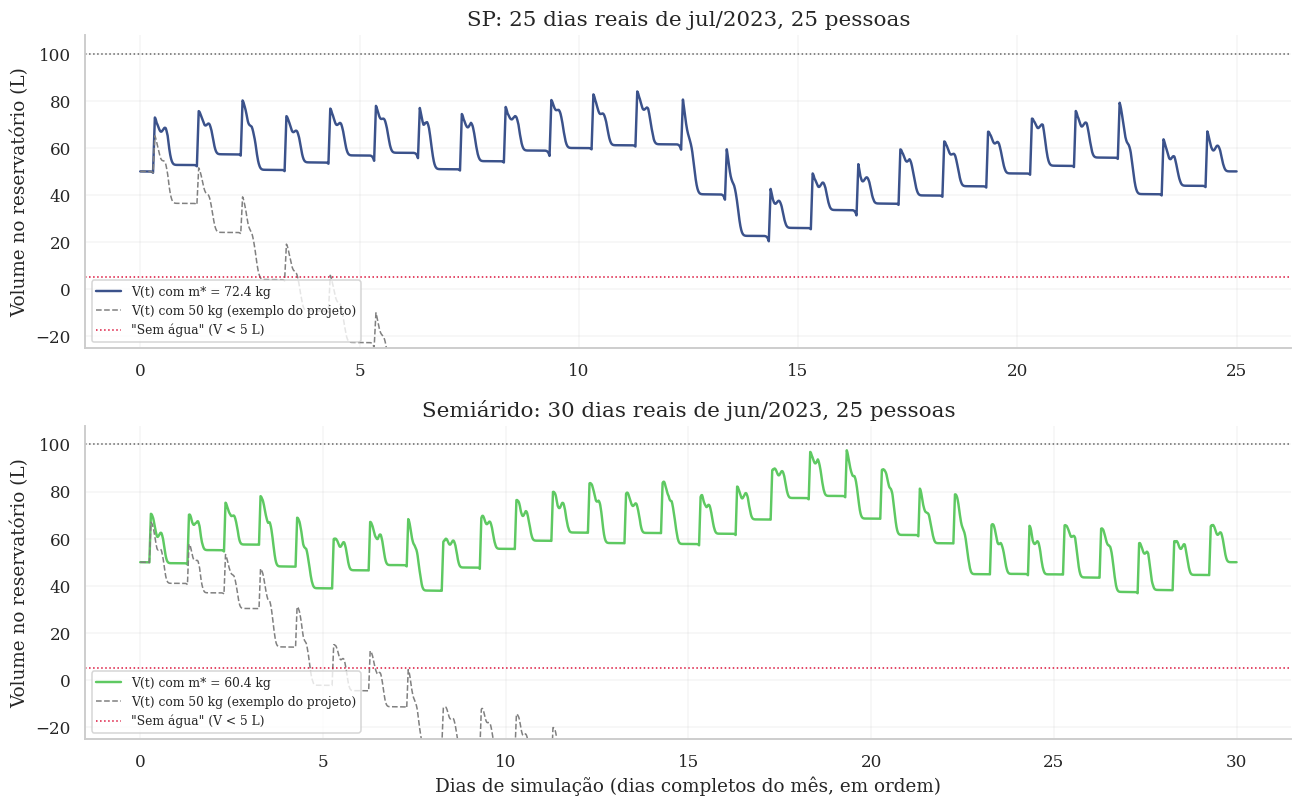

In [29]:
# volume ao longo do mês crítico
fig, eixos = plt.subplots(2, 1, figsize=(12, 7.5))
for (terr, r), ax in zip(reservatorio.items(), eixos):
    t_V = np.arange(len(r["V"])) * DT / 24
    ax.plot(t_V, r["V"], color=COR[terr], lw=1.6, label=f"V(t) com m* = {r['m_star']:.1f} kg")
    ax.plot(t_V, simular(50.0, r["p"], r["c"], cap), color="0.5", lw=1, ls="--",
            label="V(t) com 50 kg (exemplo do projeto)")
    ax.axhline(V_MIN, color="crimson", lw=1, ls=":", label=f'"Sem água" (V < {V_MIN:.0f} L)')
    ax.axhline(cap, color="0.4", lw=1, ls=":")
    ax.set(ylabel="Volume no reservatório (L)", ylim=(-0.25 * cap, 1.08 * cap),
           title=f"{terr}: {len(r['seq'])} dias reais de {NOMES_MES[MES_CRITICO[terr]]}/2023, {N_PESSOAS} pessoas")
    ax.legend(fontsize=8, loc="lower left")
eixos[-1].set_xlabel("Dias de simulação (dias completos do mês, em ordem)")
salvar(fig, "10_reservatorio")

07h59: V = 20.48 L (mínimo)
08h59: V = 41.51 L (máximo)
11h34: V = 36.26 L (mínimo)
13h26: V = 37.53 L (máximo)


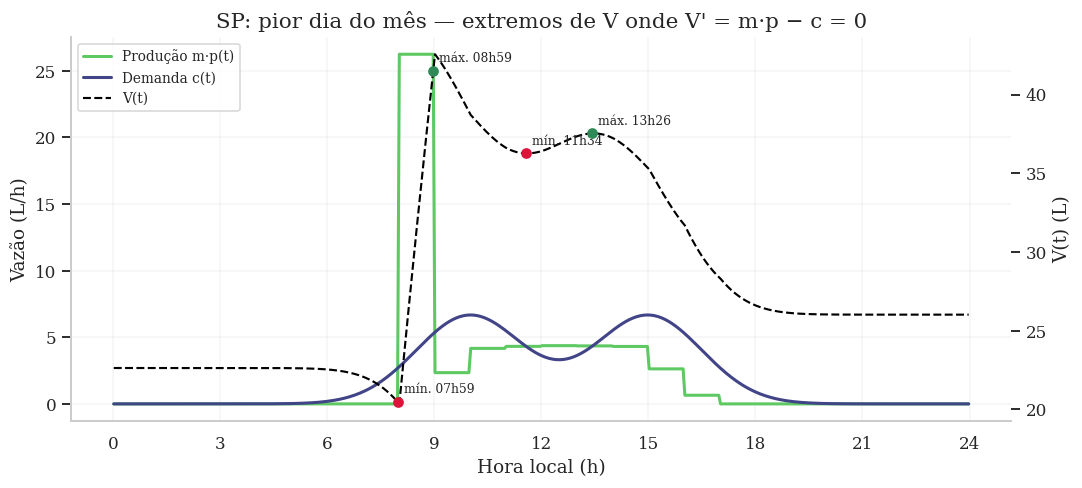

In [30]:
# extremos de V no pior dia de SP (V' = m·p − c = 0)
r = reservatorio["SP"]
dia_pior = int(np.argmin(r["V"][:-1]) * DT // 24)
janela = slice(int(dia_pior * 24 / DT), int((dia_pior + 1) * 24 / DT))
t_j = r["t"][janela] - dia_pior * 24
fluxo = r["m_star"] * r["p"][janela] - r["c"][janela]
V_j = r["V"][janela]
trocas = np.where(np.diff(np.sign(fluxo)) != 0)[0]
for i in trocas:
    print(f"{hora_txt(t_j[i])}: V = {V_j[i]:.2f} L ({'mínimo' if fluxo[i] < 0 < fluxo[i + 1] else 'máximo'})")

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(t_j, r["m_star"] * r["p"][janela], color=VIRIDIS(0.75), lw=2, label="Produção m·p(t)")
ax.plot(t_j, r["c"][janela], color=VIRIDIS(0.2), lw=2, label="Demanda c(t)")
ax2 = ax.twinx()
ax2.plot(t_j, V_j, color="k", lw=1.4, ls="--", label="V(t)")
for i in trocas:
    tipo = "mín." if fluxo[i] < 0 < fluxo[i + 1] else "máx."
    ax2.scatter([t_j[i]], [V_j[i]], color="crimson" if tipo == "mín." else "seagreen", zorder=5)
    ax2.annotate(f"{tipo} {hora_txt(t_j[i])}", xy=(t_j[i], V_j[i]), xytext=(4, 6), textcoords="offset points",
                 fontsize=8)
ax2.set_ylabel("V(t) (L)")
ax2.grid(False)
ax.set(xlabel="Hora local (h)", ylabel="Vazão (L/h)", xticks=range(0, 25, 3),
       title="SP: pior dia do mês — extremos de V onde V' = m·p − c = 0")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=9, loc="upper left")
salvar(fig, "11_extremos_reservatorio")

In [31]:
# sensibilidade ao número de pessoas
linhas = []
for n_p in [10, 25, 50]:
    for terr, r in reservatorio.items():
        c_f = demanda(r["t"] % 24, n_p)
        linhas.append({"território": terr, "pessoas": n_p,
                       "m_lim (kg)": c_f.mean() / r["p"].mean(),
                       "m* (kg)": massa_minima(r["p"], c_f, capacidade(n_p))})
tabela(pd.DataFrame(linhas).pivot(index="pessoas", columns="território", values=["m_lim (kg)", "m* (kg)"]))

m_lim (kg)            m* (kg)          
território         SP Semiárido       SP Semiárido
pessoas                                           
10            28.9512   24.1652  28.9512   24.1652
25            72.3780   60.4130  72.3780   60.4130
50           144.7561  120.8260 144.7561  120.8260

m_lim (kg)            m* (kg)          
território         SP Semiárido       SP Semiárido
pessoas                                           
10            28.9512   24.1652  28.9512   24.1652
25            72.3780   60.4130  72.3780   60.4130
50           144.7561  120.8260 144.7561  120.8260

m* (kg)                  condição ativa  \
território                          SP Semiárido                    SP   
reserva (dias) capacidade (L)                                            
0.2500         12.5000             inf       inf  inviável até 1000 kg   
0.5000         25.0000        634.1228  117.3143        nunca esvaziar   
0.7500         37.5000        281.0000   68.8118        nunca esvaziar   
1.0000         50.0000        103.0037   63.6087        nunca esvaziar   
1.5000         75.0000         72.3780   61.6217        balanço do mês   
2.0000         100.0000        72.3780   60.4130        balanço do mês   
4.0000         200.0000        72.3780   60.4130        balanço do mês   

                                                     
território                                Semiárido  
reserva (dias) capacidade (L)                        
0.2500         12.5000         inviável até 1000 kg  
0.5000         25.0000               nunca esvaziar  
0.7500         37.5000               nunca esvaziar  
1.0000         50.0000               nunca esvaziar  
1.5000         75.0000               balanço do mês  
2.0000         100.0000              balanço do mês  
4.0000         200.0000              balanço do mês

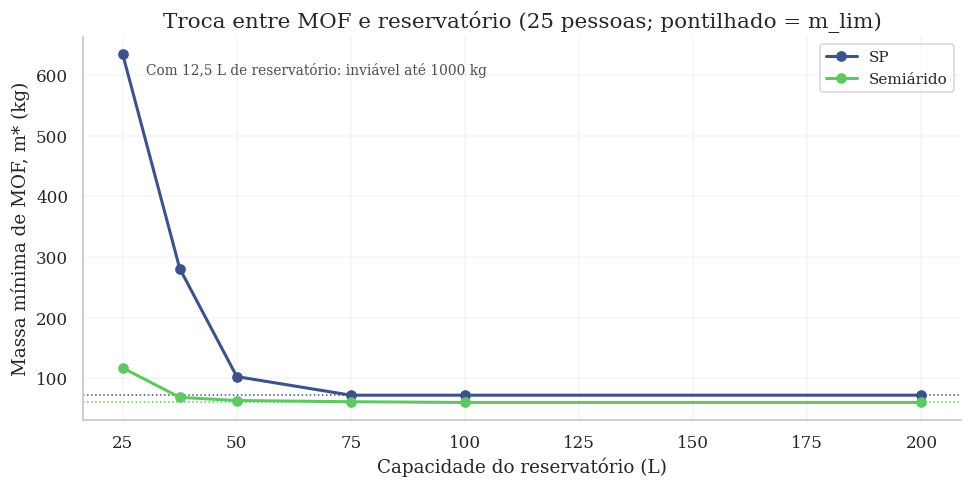

In [32]:
# troca entre massa de MOF e capacidade do reservatório
linhas = []
for dias_reserva in [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 4.0]:
    cap_v = dias_reserva * 2 * N_PESSOAS
    for terr, r in reservatorio.items():
        m_v = massa_minima(r["p"], r["c"], cap_v)
        if np.isinf(m_v):
            ativa = "inviável até 1000 kg"
        elif (V_v := simular(m_v, r["p"], r["c"], cap_v)).min() - V_MIN < V_v[-1] - V_v[0]:
            ativa = "nunca esvaziar"
        else:
            ativa = "balanço do mês"
        linhas.append({"território": terr, "reserva (dias)": dias_reserva, "capacidade (L)": cap_v,
                       "m* (kg)": m_v, "condição ativa": ativa})
troca = pd.DataFrame(linhas)
tabela(troca.pivot(index=["reserva (dias)", "capacidade (L)"], columns="território",
                   values=["m* (kg)", "condição ativa"]))

fig, ax = plt.subplots(figsize=(9, 4.6))
for terr in reservatorio:
    sub = troca[troca["território"] == terr]
    ax.plot(sub["capacidade (L)"], sub["m* (kg)"], "o-", color=COR[terr], lw=2, label=terr)
    ax.axhline(reservatorio[terr]["m_lim"], color=COR[terr], ls=":", lw=1)
ax.set(xlabel="Capacidade do reservatório (L)", ylabel="Massa mínima de MOF, m* (kg)",
       title=f"Troca entre MOF e reservatório ({N_PESSOAS} pessoas; pontilhado = m_lim)")
ax.text(30, 600, "Com 12,5 L de reservatório: inviável até 1000 kg", fontsize=9, color="0.3")
ax.legend()
salvar(fig, "10a_troca_mof_reservatorio")

## 7. Torneira: limites laterais e histerese

,h,L(5 − h),L(5 + h)
0,0.1000,1,0
1,0.0100,1,0
2,0.0010,1,0


Comutações em 2 h: regra simples = 72 | com histerese = 4


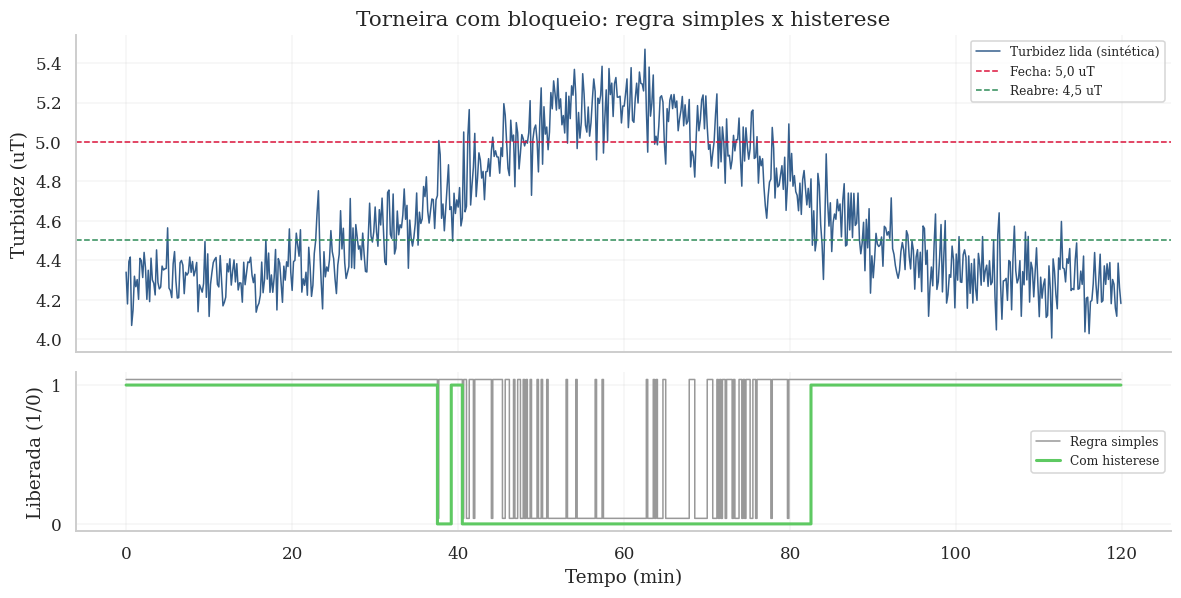

In [33]:
# L(x) = 1 se x < 5, 0 se x >= 5: limites laterais em x = 5 pela tabela de valores
def liberada(x):
    return np.where(np.asarray(x) < 5.0, 1, 0)


tabela(pd.DataFrame({"h": [0.1, 0.01, 0.001],
                     "L(5 − h)": [int(liberada(5 - h)) for h in [0.1, 0.01, 0.001]],
                     "L(5 + h)": [int(liberada(5 + h)) for h in [0.1, 0.01, 0.001]]}))

# sinal sintético de turbidez (só para testar a lógica)
rng = np.random.default_rng(42)
t_seg = np.arange(0, 2 * 3600, 10)
turbidez = 4.3 + 0.9 * np.exp(-((t_seg - 3600) / 1500) ** 2) + rng.normal(0, 0.12, len(t_seg))

simples = liberada(turbidez)
histerese = np.empty_like(simples)
estado = 1
for i, x in enumerate(turbidez):
    if estado == 1 and x >= 5.0:      # fecha em 5,0 uT
        estado = 0
    elif estado == 0 and x <= 4.5:    # reabre em 4,5 uT
        estado = 1
    histerese[i] = estado

print(f"Comutações em 2 h: regra simples = {np.sum(np.diff(simples) != 0)} | "
      f"com histerese = {np.sum(np.diff(histerese) != 0)}")

fig, eixos = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
eixos[0].plot(t_seg / 60, turbidez, color=VIRIDIS(0.3), lw=1, label="Turbidez lida (sintética)")
eixos[0].axhline(5.0, color="crimson", ls="--", lw=1, label="Fecha: 5,0 uT")
eixos[0].axhline(4.5, color="seagreen", ls="--", lw=1, label="Reabre: 4,5 uT")
eixos[0].set(ylabel="Turbidez (uT)", title="Torneira com bloqueio: regra simples x histerese")
eixos[0].legend(fontsize=8, loc="upper right")
eixos[1].step(t_seg / 60, simples + 0.04, color="0.6", lw=1, label="Regra simples")
eixos[1].step(t_seg / 60, histerese, color=VIRIDIS(0.75), lw=2, label="Com histerese")
eixos[1].set(xlabel="Tempo (min)", ylabel="Liberada (1/0)", yticks=[0, 1])
eixos[1].legend(fontsize=8, loc="center right")
salvar(fig, "12_torneira_histerese")

## 8. Síntese para a decisão

In [34]:
tabela(pd.DataFrame({
    terr: {
        "Mês crítico (2023)": NOMES_MES[MES_CRITICO[terr]],
        "Produção média no mês crítico (L/kg/dia)": mensal[terr].loc[MES_CRITICO[terr], "media"],
        "Pior dia do mês (L/kg/dia)": mensal[terr].loc[MES_CRITICO[terr], "minimo"],
        "Tempo de adsorção ótimo médio de dia (h)": mensal[terr].loc[MES_CRITICO[terr], "tau"],
        f"m_lim para {N_PESSOAS} pessoas (kg)": reservatorio[terr]["m_lim"],
        f"m* para {N_PESSOAS} pessoas (kg)": reservatorio[terr]["m_star"],
        "Reservatório adotado (L)": capacidade(N_PESSOAS),
        "Pessoas-dia com 50 kg no mês crítico": 50 * mensal[terr].loc[MES_CRITICO[terr], "media"] / 2,
    } for terr in clima}))

# conferência da seção 9.2 do projeto: 1000 estações × 50 L/dia
anual = 1000 * 50 * 365
print(f"{anual / 1e6:.2f} milhões de L/ano = {100 * anual / 105e9:.4f} % de 105 bilhões de L")

,SP,Semiárido
Mês crítico (2023),jul,jun
Produção média no mês crítico (L/kg/dia),0.6908,0.8276
Pior dia do mês (L/kg/dia),0.3974,0.6103
Tempo de adsorção ótimo médio de dia (h),2.0811,1.6163
m_lim para 25 pessoas (kg),72.3780,60.4130
m* para 25 pessoas (kg),72.3780,60.4130
Reservatório adotado (L),100.0000,100.0000
Pessoas-dia com 50 kg no mês crítico,17.2704,20.6909


18.25 milhões de L/ano = 0.0174 % de 105 bilhões de L
